<a href="https://colab.research.google.com/github/savagithubs/pediatric-pneumonia-detection-with-deep-learning-for-bmi6334/blob/main/6334_Final_project_report_paper_Code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Deep Learning for Pediatric Pneumonia Detection Using Chest X-Ray Images**

# Author: Mwidy Mounange-Badimi

### BMI 6334 Deep Learning in Biomedical Informatics

## Cell 0 – bootstrap (install, download, set DATA_ROOT)


### **Cell 0 – Environment Setup, Data Acquisition, and Configuration**

This cell sets up the notebook environment by installing missing dependencies (`kaggle`, `albumentations`), uploading the Kaggle API key to authenticate access, and downloading the pediatric chest X-ray dataset from Kaggle. After extraction, the dataset path is explicitly defined to avoid ambiguity. Key training hyperparameters are configured, including image size, batch size, and total epochs. Finally, mixed-precision training is activated to improve GPU memory efficiency and computational speed—an important step when working with high-resolution images and deep models.


In [ ]:
# minimal deps (Colab already has TF 2.19)
!pip install -q kaggle albumentations

# ── upload your Kaggle API key ──
from google.colab import files
files.upload()        # choose kaggle.json

# move & protect the key
!mkdir -p ~/.kaggle && cp kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json

# download & unzip the dataset (contains nested chest_xray/chest_xray/)
!kaggle datasets download -d paultimothymooney/chest-xray-pneumonia -p /content --unzip -q

# point unambiguously at the inner folder
DATA_ROOT  = '/content/chest_xray/chest_xray'
IMG_SIZE   = 299
BATCH_SIZE = 128         # fits on an A100
EPOCHS     = 15

# optional: mixed-precision for speed/memory
from tensorflow.keras import mixed_precision
mixed_precision.set_global_policy('mixed_float16')


Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia
License(s): other


## Cell 1 – imports


In [ ]:
import os, cv2, random, numpy as np
import albumentations as A
import tensorflow as tf
from sklearn.model_selection import train_test_split
from tensorflow.keras import layers, models
from tensorflow.keras.applications import Xception
from tensorflow.keras.metrics import AUC, Recall

## Cell 2 – lung‐mask + preprocess function


In [ ]:
def _lung_mask(gray: np.ndarray) -> np.ndarray:
    _, thr = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    cnts, _ = cv2.findContours(255 - thr, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not cnts:
        return np.ones_like(gray, np.uint8) * 255
    biggest = max(cnts, key=cv2.contourArea)
    mask = np.zeros_like(gray, np.uint8)
    cv2.drawContours(mask, [biggest], -1, 255, -1)
    return mask

def preprocess_and_crop(path):
    if isinstance(path, tf.Tensor):
        path = path.numpy().decode()
    gray = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if gray is None:
        raise FileNotFoundError(path)

    mask = _lung_mask(gray)
    x, y, w, h = cv2.boundingRect(mask)
    crop   = gray[y:y+h, x:x+w]
    resize = cv2.resize(crop, (IMG_SIZE, IMG_SIZE))
    rgb    = cv2.cvtColor(resize, cv2.COLOR_GRAY2RGB)
    return rgb.astype('float32') / 255.0


## Cell 3 – Albumentations pipeline


In [ ]:
aug = A.Compose([
    A.CLAHE(p=0.3),
    A.RandomBrightnessContrast(p=0.3),
    A.ShiftScaleRotate(rotate_limit=15, p=0.5),
    A.Rotate(limit=5, p=0.3),
    A.HorizontalFlip(p=0.5),
    A.GaussNoise(p=0.2),
    A.OneOf([A.MotionBlur(), A.MedianBlur(), A.Blur()], p=0.2),
])


/usr/local/lib/python3.11/dist-packages/albumentations/core/validation.py:87: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


## Cell 4 – explicit 80/10/10 train/val/test split


In [ ]:
# Cell 4 – explicit 80/10/10 train/val/test split (with hidden-file filter)

all_paths, all_labels = [], []
for cls in ['PNEUMONIA', 'NORMAL']:
    label = 1 if cls == 'PNEUMONIA' else 0
    for phase in ['train','val','test']:
        full_dir = os.path.join(DATA_ROOT, phase, cls)
        for fname in os.listdir(full_dir):
            # skip hidden / system files like .DS_Store
            if fname.startswith('.'):
                continue
            all_paths.append(os.path.join(full_dir, fname))
            all_labels.append(label)

all_paths  = np.array(all_paths)
all_labels = np.array(all_labels)

# rest of your splits unchanged…
train_p, tmp_p, train_l, tmp_l = train_test_split(
    all_paths, all_labels,
    test_size=0.2,
    stratify=all_labels,
    random_state=42
)
val_p, test_p, val_l, test_l = train_test_split(
    tmp_p, tmp_l,
    test_size=0.5,
    stratify=tmp_l,
    random_state=42
)

print(f"→ train: {len(train_p)}  val: {len(val_p)}  test: {len(test_p)}")


→ train: 4684  val: 586  test: 586


## Cell 5 – build `tf.data.Dataset`s


In [ ]:
def make_ds(pths, lbs, *, augment=False):
    ds = tf.data.Dataset.from_tensor_slices((pths, lbs))

    def _load(path, label):
        img = tf.py_function(preprocess_and_crop, [path], tf.float32)
        img.set_shape((IMG_SIZE, IMG_SIZE, 3))
        if augment:
            img = tf.numpy_function(
                lambda x: aug(image=(x*255).astype('uint8'))['image'].astype('float32')/255.0,
                [img], tf.float32
            )
            img.set_shape((IMG_SIZE, IMG_SIZE, 3))
        return img, label

    ds = ds.map(_load, num_parallel_calls=tf.data.AUTOTUNE)
    if augment:
        ds = ds.shuffle(4096, seed=42)
    ds = ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    return ds

train_ds = make_ds(train_p, train_l, augment=True)
val_ds   = make_ds(val_p,   val_l,   augment=False)
test_ds  = make_ds(test_p,  test_l,  augment=False)

print("Datasets ready → train/val/test")


Datasets ready → train/val/test


## Cell 6 – Xception backbone + compile


In [ ]:
base = Xception(
    weights='imagenet', include_top=False,
    input_shape=(IMG_SIZE,IMG_SIZE,3), pooling='avg'
)
for layer in base.layers[:-10]:
    layer.trainable = False

x   = layers.Dense(512, activation='relu')(base.output)
x   = layers.Dropout(0.4)(x)
out = layers.Dense(1, dtype='float32', activation='sigmoid')(x)

model = models.Model(base.input, out)
model.compile(
    optimizer='adam',
    loss=tf.keras.losses.BinaryFocalCrossentropy(alpha=0.25, gamma=2.0),
    metrics=['accuracy', AUC(name='auc'), AUC(curve='PR', name='pr_auc'), Recall(name='recall')]
)
model.summary(line_length=100)


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                ┃ Output Shape            ┃        Param # ┃ Connected to            ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)  │ (None, 299, 299, 3)     │              0 │ -                       │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ cast_2 (Cast)               │ (None, 299, 299, 3)     │              0 │ input_layer_1[0][0]     │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ block1_conv1 (Conv2D)       │ (None, 149, 149, 32)    │            864 │ cast_2[0][0]            │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ block1_conv1_bn             │ (None, 149, 149, 32)    │            128 │ block1_conv1[0][0]      │
│ (BatchNormalization)        │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ block1_conv1_act            │ (None, 149, 149, 32)    │              0 │ block1_conv1_bn[0][0]   │
│ (Activation)                │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ block1_conv2 (Conv2D)       │ (None, 147, 147, 64)    │         18,432 │ block1_conv1_act[0][0]  │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ block1_conv2_bn             │ (None, 147, 147, 64)    │            256 │ block1_conv2[0][0]      │
│ (BatchNormalization)        │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ block1_conv2_act            │ (None, 147, 147, 64)    │              0 │ block1_conv2_bn[0][0]   │
│ (Activation)                │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ block2_sepconv1             │ (None, 147, 147, 128)   │          8,768 │ block1_conv2_act[0][0]  │
│ (SeparableConv2D)           │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ block2_sepconv1_bn          │ (None, 147, 147, 128)   │            512 │ block2_sepconv1[0][0]   │
│ (BatchNormalization)        │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ block2_sepconv2_act         │ (None, 147, 147, 128)   │              0 │ block2_sepconv1_bn[0][… │
│ (Activation)                │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ block2_sepconv2             │ (None, 147, 147, 128)   │         17,536 │ block2_sepconv2_act[0]… │
│ (SeparableConv2D)           │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ block2_sepconv2_bn          │ (None, 147, 147, 128)   │            512 │ block2_sepconv2[0][0]   │
│ (BatchNormalization)        │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ conv2d_4 (Conv2D)           │ (None, 74, 74, 128)     │          8,192 │ block1_conv2_act[0][0]  │
├─────────────────────────────┼─────────────────────────┼────

 Total params: 21,911,081 (83.58 MB)

 Trainable params: 5,800,449 (22.13 MB)

 Non-trainable params: 16,110,632 (61.46 MB)

## Cell 7 – quick benchmark (1 epoch)


In [ ]:
history = model.fit(
    train_ds, validation_data=val_ds,
    epochs=1,   # smoke test
    callbacks=[tf.keras.callbacks.EarlyStopping(
        monitor='val_auc', patience=1, mode='max', restore_best_weights=True
    )]
)
print(f"▶ val-AUC after 1 epoch: {history.history['val_auc'][-1]:.4f}")


37/37 ━━━━━━━━━━━━━━━━━━━━ 228s 3s/step - accuracy: 0.7473 - auc: 0.7275 - loss: 0.1626 - pr_auc: 0.8747 - recall: 0.8590 - val_accuracy: 0.8959 - val_auc: 0.9584 - val_loss: 0.0811 - val_pr_auc: 0.9857 - val_recall: 0.9508
▶ val-AUC after 1 epoch: 0.9584


## Cell 8 – Phase 2 gradual unfreeze


In [ ]:
# 1) unfreeze all
for layer in base.layers:
    layer.trainable = True

# 2) lower LR
model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-4),
    loss=tf.keras.losses.BinaryFocalCrossentropy(alpha=0.25, gamma=2.0),
    metrics=['accuracy', AUC(name='auc'), Recall(name='recall')]
)

# 3) continue training
history2 = model.fit(
    train_ds, validation_data=val_ds,
    initial_epoch=1, epochs=EPOCHS,
    callbacks=[tf.keras.callbacks.EarlyStopping(
        monitor='val_auc', patience=3, mode='max', restore_best_weights=True
    )]
)

print(f"▶ best val-AUC: {max(history2.history['val_auc']):.4f}")


Epoch 2/15
37/37 ━━━━━━━━━━━━━━━━━━━━ 236s 2s/step - accuracy: 0.8575 - auc: 0.9123 - loss: 0.0869 - recall: 0.9322 - val_accuracy: 0.8874 - val_auc: 0.9703 - val_loss: 0.0949 - val_recall: 0.9696
Epoch 3/15
37/37 ━━━━━━━━━━━━━━━━━━━━ 110s 784ms/step - accuracy: 0.8937 - auc: 0.9520 - loss: 0.0655 - recall: 0.9445 - val_accuracy: 0.9215 - val_auc: 0.9774 - val_loss: 0.0905 - val_recall: 0.9813
Epoch 4/15
37/37 ━━━━━━━━━━━━━━━━━━━━ 109s 783ms/step - accuracy: 0.9138 - auc: 0.9698 - loss: 0.0516 - recall: 0.9419 - val_accuracy: 0.9334 - val_auc: 0.9789 - val_loss: 0.0623 - val_recall: 0.9813
Epoch 5/15
37/37 ━━━━━━━━━━━━━━━━━━━━ 110s 781ms/step - accuracy: 0.9304 - auc: 0.9750 - loss: 0.0479 - recall: 0.9605 - val_accuracy: 0.9317 - val_auc: 0.9760 - val_loss: 0.0666 - val_recall: 0.9766
Epoch 6/15
37/37 ━━━━━━━━━━━━━━━━━━━━ 110s 789ms/step - accuracy: 0.9373 - auc: 0.9793 - loss: 0.0431 - recall: 0.9582 - val_accuracy: 0.9454 - val_auc: 0.9825 - val_loss: 0.0546 - val_recall: 0.9836
Epo

## Cell 9 – final evaluation on the held-out test set


In [ ]:
# Evaluate on the never-seen test set
test_metrics = model.evaluate(test_ds)
print("Test set metrics:", dict(zip(model.metrics_names, test_metrics)))



5/5 ━━━━━━━━━━━━━━━━━━━━ 15s 3s/step - accuracy: 0.9625 - auc: 0.9917 - loss: 0.0395 - recall: 0.9570
Test set metrics: {'loss': 0.03853499889373779, 'compile_metrics': 0.9624573588371277}


## 9.a) Training vs. Validation AUC


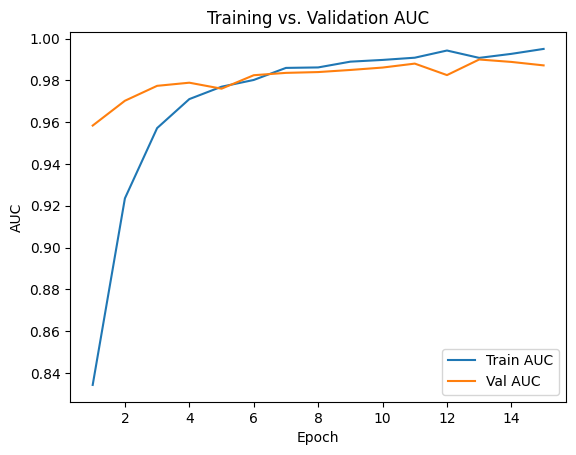

In [ ]:
import matplotlib.pyplot as plt

# 1) Grab the actual epoch numbers
#    history.epoch is a list of epoch indices (e.g. [0]) → +1 → [1]
#    history2.epoch might be [1,2,3,...] because initial_epoch=1
ep1 = [e + 1 for e in history.epoch]
ep2 = [e + 1 for e in history2.epoch]

# 2) Concatenate epoch lists and metric lists
all_epochs = ep1 + ep2
train_auc  = history.history['auc']    + history2.history['auc']
val_auc    = history.history['val_auc'] + history2.history['val_auc']

# 3) Plot
plt.plot(all_epochs, train_auc, label='Train AUC')
plt.plot(all_epochs, val_auc,   label='Val AUC')
plt.xlabel('Epoch')
plt.ylabel('AUC')
plt.title('Training vs. Validation AUC')
plt.legend()
plt.show()


## 9.c) – ROC Curve on the Test Set


5/5 ━━━━━━━━━━━━━━━━━━━━ 19s 3s/step


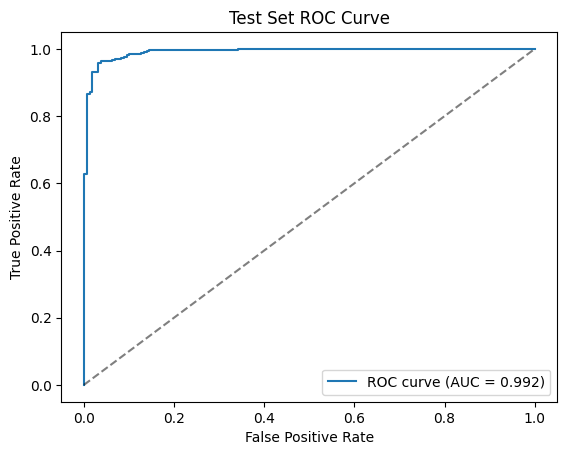

In [ ]:
import numpy as np
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# 1) Extract true labels and predicted scores from test_ds
y_true = np.concatenate([y.numpy() for _, y in test_ds], axis=0)
y_pred = model.predict(test_ds).ravel()

# 2) Compute ROC metrics
fpr, tpr, _ = roc_curve(y_true, y_pred)
roc_auc = auc(fpr, tpr)

# 3) Plot ROC curve
plt.plot(fpr, tpr, label=f'ROC curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], 'k--', alpha=0.5)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Test Set ROC Curve')
plt.legend(loc='lower right')
plt.show()


## Cell 10 – Post-training diagnostics


In [ ]:
## Cell 10a – Imports for diagnostics
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, f1_score
from sklearn.calibration import calibration_curve
import random, matplotlib.image as mpimg

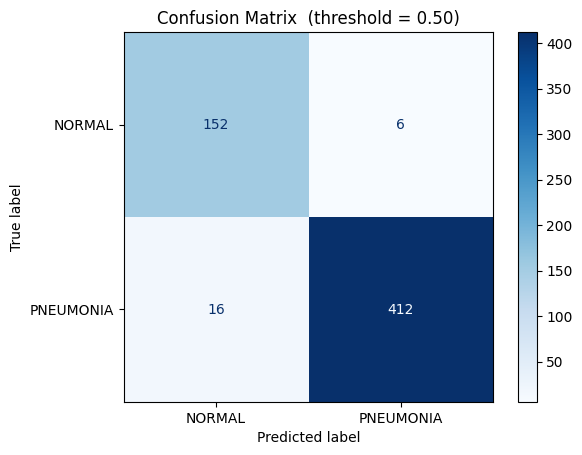

In [ ]:
## Cell 10b – Confusion Matrix (threshold = 0.5)

# binarize predictions at 0.5
y_pred_bin = (y_pred >= 0.5).astype(int)

# compute & display
cm = confusion_matrix(y_true, y_pred_bin)
disp = ConfusionMatrixDisplay(cm, display_labels=['NORMAL', 'PNEUMONIA'])
disp.plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix  (threshold = 0.50)')
plt.show()


Best F1 = 0.974 at threshold = 0.49


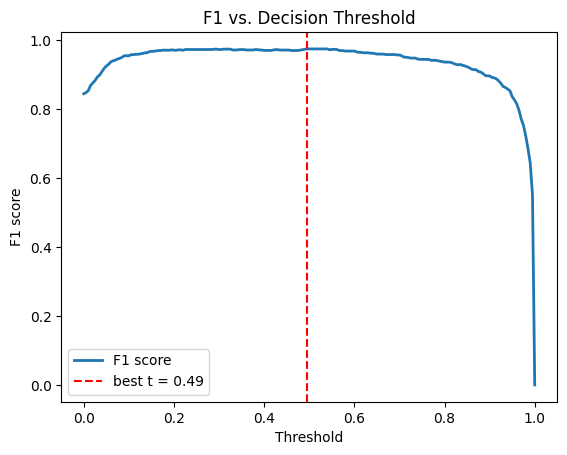

In [ ]:
## Cell 10c – F1 vs. Decision Threshold

# sweep thresholds
thresholds = np.linspace(0, 1, 201)
f1s        = [f1_score(y_true, y_pred >= t) for t in thresholds]

# find best
best_idx   = int(np.argmax(f1s))
best_t, best_f1 = thresholds[best_idx], f1s[best_idx]
print(f'Best F1 = {best_f1:.3f} at threshold = {best_t:.2f}')

# plot
plt.plot(thresholds, f1s, label='F1 score', lw=2)
plt.axvline(best_t, ls='--', color='red', label=f'best t = {best_t:.2f}')
plt.xlabel('Threshold')
plt.ylabel('F1 score')
plt.title('F1 vs. Decision Threshold')
plt.legend()
plt.show()


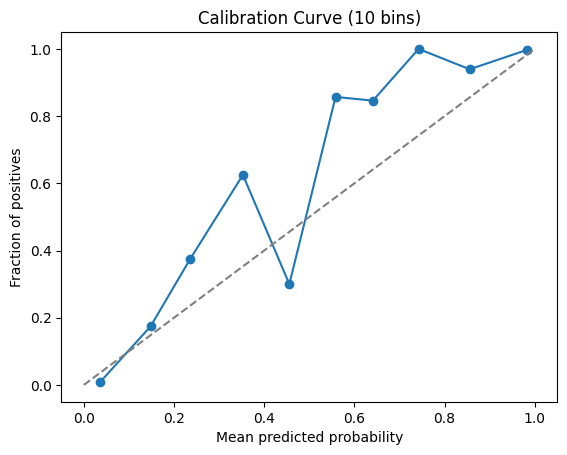

In [ ]:
## Cell 10d – Calibration Curve

prob_true, prob_pred = calibration_curve(
    y_true, y_pred, n_bins=10, strategy='uniform'
)

plt.plot(prob_pred, prob_true, marker='o')
plt.plot([0, 1], [0, 1], '--', color='gray')
plt.xlabel('Mean predicted probability')
plt.ylabel('Fraction of positives')
plt.title('Calibration Curve (10 bins)')
plt.show()


# false positives: 6
# false negatives: 16


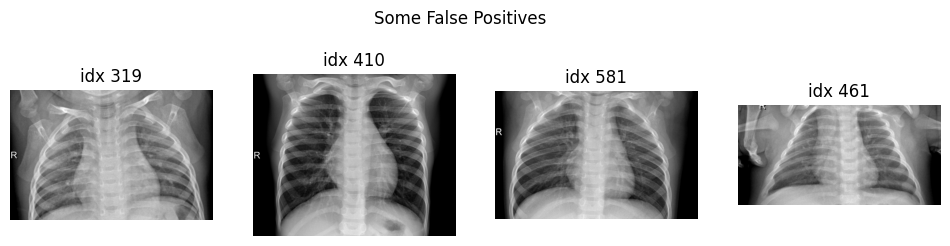

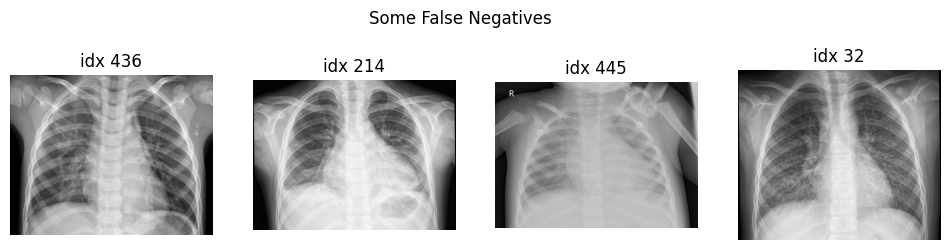

In [ ]:
## Cell 10e – False-Positive / False-Negative Gallery

# find indices
fp_idx = np.where((y_true == 0) & (y_pred >= 0.5))[0]
fn_idx = np.where((y_true == 1) & (y_pred < 0.5))[0]
print(f'# false positives: {len(fp_idx)}')
print(f'# false negatives: {len(fn_idx)}')

# helper to show up to 4 examples
def show_examples(idxs, title):
    if len(idxs) == 0:
        print(f'No {title.lower()} to display.')
        return
    sel = random.sample(list(idxs), min(4, len(idxs)))
    plt.figure(figsize=(12, 3))
    for i, idx in enumerate(sel, 1):
        img = mpimg.imread(test_p[idx])
        plt.subplot(1, len(sel), i)
        plt.imshow(img, cmap='gray')
        plt.axis('off')
        plt.title(f'idx {idx}')
    plt.suptitle(title)
    plt.show()

show_examples(fp_idx, 'Some False Positives')
show_examples(fn_idx, 'Some False Negatives')
